# 11. Modelo base: líneas base triviales y SVR lineal

**Ruta D (regresión espacio-temporal).** El enunciado pide un modelo base (SVR lineal) comparado con
líneas base triviales. Se usan cinco, todas sin aprendizaje o con aprendizaje mínimo:

| Línea base | Pronóstico para la celda *c* en el mes *t* + 1 |
|---|---|
| `DummyRegressor` (media) | media global del objetivo en entrenamiento |
| `DummyRegressor` (mediana) | 0, la mediana (el «nunca pasa nada») |
| Media por celda (zona) | media del objetivo de la celda en entrenamiento |
| Persistencia | sismos de la celda en el mes *t* |
| Ingenuo estacional | sismos de la celda en el mismo mes del año anterior |

**Métrica principal: RMSLE.** Complementarias: RMSE, MAE, MAPE (solo y > 0), sMAPE, R² y R² en log.
La partición, la validación cruzada y el Pipeline son los de los capítulos 1, 7 y 10.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Librerías, datos y pliegues temporales del modelo base
import time
import warnings
warnings.filterwarnings("ignore")
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, GroupKFold
from statsmodels.graphics.tsaplots import plot_acf
from src import modelos as mdl
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"].astype(float); tm = info["tm"]; cc = info["cc"]
par = pd.read_csv(cfg.TABLAS / "parametros_preprocesamiento.csv").set_index("parametro")["valor"]
IMPUT = par["imputacion_magnitud"]; COLS = par["variables"].split(";")
pl = datos.pliegues_temporales(tm[tr])
md(f"Imputación de magnitudes: **{IMPUT}**; variables: **{len(COLS)}** (capítulo 10).")

Imputación de magnitudes: **constante**; variables: **18** (capítulo 10).

## 11.1 Hiperparámetros del SVR lineal (solo con validación cruzada temporal)

- **C** controla la regularización: a menor C, más regularización. Se explora en escala logarítmica.
- **ε** es el ancho del tubo insensible de la pérdida, en escala log1p. ε = 0 equivale a una regresión
  robusta de tipo L1, que estima la **mediana** condicional en log1p.

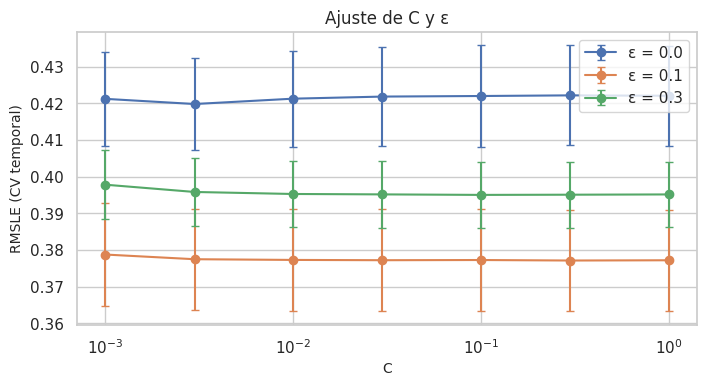

**Interpretación.** El mejor par es **C = 0.3, ε = 0.1** (RMSLE de validación 0,3771 ± 0,0308).
- La curva es plana para C ≥ 0,01: el modelo apenas cambia al regularizar menos, señal de que no hay sobreajuste por exceso de parámetros.
- Un ε grande empeora el error: con 76 % de ceros, un tubo ancho ignora la diferencia entre 0 y 1 sismo, que es justamente lo que mide el RMSLE.
- La prueba no se usó en ninguna de estas decisiones.

In [3]:
# Búsqueda en rejilla de C y ε del SVR lineal con CV temporal
rejilla = [(C, e) for C in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0) for e in (0.0, 0.1, 0.3)]
filas = []
for C, e in rejilla:
    r = []
    for a, v in pl:
        m_ = mdl.svr_lineal(COLS, C=C, epsilon=e, imputacion_magnitud=IMPUT).fit(X.iloc[tr[a]][COLS], y[tr[a]])
        r.append(ev.rmsle(y[tr[v]], m_.predict(X.iloc[tr[v]][COLS])))
    filas.append({"C": C, "epsilon": e, "RMSLE_CV": np.mean(r), "desv": np.std(r)})
hp = pd.DataFrame(filas)
mejor = hp.loc[hp.RMSLE_CV.idxmin()]
C_OPT, EPS_OPT = float(mejor.C), float(mejor.epsilon)
eda.guardar_tabla(hp, "svr_hiperparametros.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
for e, g in hp.groupby("epsilon"):
    ax.errorbar(g.C, g.RMSLE_CV, yerr=g.desv / np.sqrt(len(pl)), marker="o", capsize=3, label=f"ε = {e}")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("RMSLE (CV temporal)"); ax.legend(); ax.set_title("Ajuste de C y ε")
eda.guardar_figura(fig, "11_hiperparametros.png"); plt.show()
md(f"""**Interpretación.** El mejor par es **C = {C_OPT}, ε = {EPS_OPT}** (RMSLE de validación {es(mejor.RMSLE_CV, 4)} ± {es(mejor.desv, 4)}).
- La curva es plana para C ≥ 0,01: el modelo apenas cambia al regularizar menos, señal de que no hay sobreajuste por exceso de parámetros.
- Un ε grande empeora el error: con 76 % de ceros, un tubo ancho ignora la diferencia entre 0 y 1 sismo, que es justamente lo que mide el RMSLE.
- La prueba no se usó en ninguna de estas decisiones.""")

## 11.2 Validación cruzada: temporal (principal), bloques espaciales y aleatoria

- **Temporal (principal):** ventana creciente con gap de un mes (5 pliegues). Mide lo que importa:
  pronosticar meses futuros.
- **Bloques espaciales:** `GroupKFold` (5 grupos) con bloques de 2° × 2°. Las celdas a una celda de
  distancia del bloque de validación (≈ 55 km) se **excluyen del entrenamiento** (buffer). Mide la
  generalización a **zonas no vistas**.
- **Aleatoria (KFold):** se incluye **solo para mostrar el optimismo** de ignorar la estructura.

In [4]:
# Modelos base (SVR lineal y líneas triviales) evaluados con tres esquemas de validación
def modelos_base():
    return {
        "Dummy (media)": lambda: DummyRegressor(strategy="mean"),
        "Dummy (mediana = 0)": lambda: DummyRegressor(strategy="median"),
        "SVR lineal": lambda: mdl.svr_lineal(COLS, C=C_OPT, epsilon=EPS_OPT, imputacion_magnitud=IMPUT),
    }

def evaluar(nombre, idx_a, idx_v):
    if nombre == "Persistencia":
        return info["persist"][idx_v]
    if nombre == "Ingenuo estacional":
        return info["estacional"][idx_v]
    if nombre == "Media por celda":
        return mdl.MediaPorCelda().fit(cc[idx_a], y[idx_a]).predict(cc[idx_v])
    m_ = modelos_base()[nombre]().fit(X.iloc[idx_a][COLS], y[idx_a])
    return m_.predict(X.iloc[idx_v][COLS])

nombres = ["Dummy (media)", "Dummy (mediana = 0)", "Media por celda", "Persistencia", "Ingenuo estacional", "SVR lineal"]
lat_c, lon_c = datos.centro_celda(cc[tr])
bloque = (np.floor((lat_c - cfg.LAT_MIN) / 2).astype(int) * 100 + np.floor((lon_c - cfg.LON_MIN) / 2).astype(int))
esquemas = {"temporal (ventana creciente + gap)": [(tr[a], tr[v]) for a, v in pl]}
gkf = []
for a, v in GroupKFold(5).split(tr, groups=bloque):
    lv, lo_v = lat_c[v], lon_c[v]
    cerca = np.zeros(len(a), bool)
    for la_, lo_ in set(zip(lv, lo_v)):
        cerca |= (np.abs(lat_c[a] - la_) <= cfg.CELDA_GRADOS + 1e-9) & (np.abs(lon_c[a] - lo_) <= cfg.CELDA_GRADOS + 1e-9)
    gkf.append((tr[a[~cerca]], tr[v]))
esquemas["bloques espaciales 2° + buffer"] = gkf
esquemas["aleatoria (KFold, optimista)"] = [(tr[a], tr[v]) for a, v in KFold(5, shuffle=True, random_state=cfg.SEMILLA).split(tr)]
filas = []
for esq, pliegues in esquemas.items():
    for n in nombres:
        r = [ev.rmsle(y[v], evaluar(n, a, v)) for a, v in pliegues]
        filas.append({"esquema": esq, "modelo": n, "RMSLE_media": np.mean(r), "RMSLE_desv": np.std(r)})
cv = pd.DataFrame(filas)
eda.guardar_tabla(cv, "cv_resumen.csv")
tabla_cv = cv.pivot(index="modelo", columns="esquema", values="RMSLE_media").loc[nombres]
tabla_cv.round(4)

esquema,"aleatoria (KFold, optimista)",bloques espaciales 2° + buffer,temporal (ventana creciente + gap)
modelo,,,
Dummy (media),0.6307,0.6558,0.6406
Dummy (mediana = 0),0.5633,0.5271,0.5511
Media por celda,0.3964,0.6558,0.4249
Persistencia,0.4707,0.4704,0.4718
Ingenuo estacional,0.5009,0.5005,0.4953
SVR lineal,0.3787,0.4841,0.3771


In [5]:
# Lectura de la comparación entre esquemas de validación
T_, E_, A_ = "temporal (ventana creciente + gap)", "bloques espaciales 2° + buffer", "aleatoria (KFold, optimista)"
t_cv = tabla_cv
md(f"""**Interpretación.**
- **Temporal (esquema principal).** El SVR lineal tiene el menor RMSLE ({es(t_cv.loc['SVR lineal', T_], 4)}). Le sigue la media por celda
  ({es(t_cv.loc['Media por celda', T_], 4)}). La persistencia ({es(t_cv.loc['Persistencia', T_], 4)}) y el ingenuo estacional ({es(t_cv.loc['Ingenuo estacional', T_], 4)})
  superan a los Dummy, pero quedan lejos de la media por celda: copiar un solo mes ruidoso es peor que usar el nivel típico de la celda.
- **Bloques espaciales.** En zonas no vistas, el SVR empeora a {es(t_cv.loc['SVR lineal', E_], 4)}, y la media por celda deja de ser aplicable (usa la
  media global, {es(t_cv.loc['Media por celda', E_], 4)}). Es el costo de generalizar a otras zonas: no es el uso previsto, pero cuantifica el riesgo.
- **Aleatoria.** El KFold aleatorio da {es(t_cv.loc['SVR lineal', A_], 4)} para el SVR, prácticamente igual a la temporal. Con 18 variables solo del pasado,
  el modelo lineal no tiene cómo «memorizar» el futuro. En cambio, la media por celda sí sale más optimista con KFold
  ({es(t_cv.loc['Media por celda', A_], 4)} frente a {es(t_cv.loc['Media por celda', T_], 4)}), porque promedia meses futuros de la misma celda. Por esa razón
  no se usa para decidir.""")

**Interpretación.**
- **Temporal (esquema principal).** El SVR lineal tiene el menor RMSLE (0,3771). Le sigue la media por celda
  (0,4249). La persistencia (0,4718) y el ingenuo estacional (0,4953)
  superan a los Dummy, pero quedan lejos de la media por celda: copiar un solo mes ruidoso es peor que usar el nivel típico de la celda.
- **Bloques espaciales.** En zonas no vistas, el SVR empeora a 0,4841, y la media por celda deja de ser aplicable (usa la
  media global, 0,6558). Es el costo de generalizar a otras zonas: no es el uso previsto, pero cuantifica el riesgo.
- **Aleatoria.** El KFold aleatorio da 0,3787 para el SVR, prácticamente igual a la temporal. Con 18 variables solo del pasado,
  el modelo lineal no tiene cómo «memorizar» el futuro. En cambio, la media por celda sí sale más optimista con KFold
  (0,3964 frente a 0,4249), porque promedia meses futuros de la misma celda. Por esa razón
  no se usa para decidir.

## 11.3 Ajuste final y evaluación única en la prueba

El SVR lineal se reajusta con **todo el entrenamiento** y se evalúa **una sola vez** en la prueba
(enero de 2021 a septiembre de 2026). Los intervalos de confianza del 95 % se obtienen con **bootstrap
por bloques de meses** (2.000 réplicas, percentil y BCa).

In [6]:
# Ajuste final en entrenamiento y predicción en prueba de todos los modelos base
t0 = time.time()
svr = modelos_base()["SVR lineal"]().fit(X.iloc[tr][COLS], y[tr])
t_ajuste = time.time() - t0
preds = {n: evaluar(n, tr, te) for n in nombres if n != "SVR lineal"}
preds["SVR lineal"] = svr.predict(X.iloc[te][COLS])
pred_tr_svr = svr.predict(X.iloc[tr][COLS])
res = pd.DataFrame([{"modelo": n, **ev.metricas_regresion(y[te], p)} for n, p in preds.items()]).set_index("modelo").loc[nombres]
ic = pd.concat({n: ev.bootstrap_meses(y[te], preds[n], tm[te]).set_index("métrica") for n in nombres})
eda.guardar_tabla(res.reset_index(), "resultados_prueba.csv")
eda.guardar_tabla(ic.reset_index().rename(columns={"level_0": "modelo"}), "intervalos_bootstrap.csv")
ic_rmsle = ic.xs("RMSLE", level=1)[["valor", "IC_BCa_inf", "IC_BCa_sup"]]
display(res.round(4))
ic_rmsle.round(4)

,RMSLE,RMSE,MAE,MAPE_y>0_%,sMAPE_%,R2,R2_log
modelo,,,,,,,
Dummy (media),0.6498,9.3918,1.3993,36.4407,169.2606,-0.0002,-0.5276
Dummy (mediana = 0),0.5662,9.4368,0.9276,100.0000,41.6111,-0.0098,-0.1599
Media por celda,0.3972,7.2083,0.6712,62.0184,178.1431,0.4108,0.4293
Persistencia,0.4363,7.0671,0.5672,78.4254,50.2676,0.4337,0.3114
Ingenuo estacional,0.4575,7.2902,0.6367,82.9614,52.1785,0.3974,0.2428
SVR lineal,0.3635,7.9072,0.7048,78.3211,116.4032,0.2911,0.5218


,valor,IC_BCa_inf,IC_BCa_sup
Dummy (media),0.6498,0.6419,0.6661
Dummy (mediana = 0),0.5662,0.5526,0.5907
Media por celda,0.3972,0.3828,0.4275
Persistencia,0.4363,0.4240,0.4584
Ingenuo estacional,0.4575,0.4422,0.4871
SVR lineal,0.3635,0.3487,0.3911


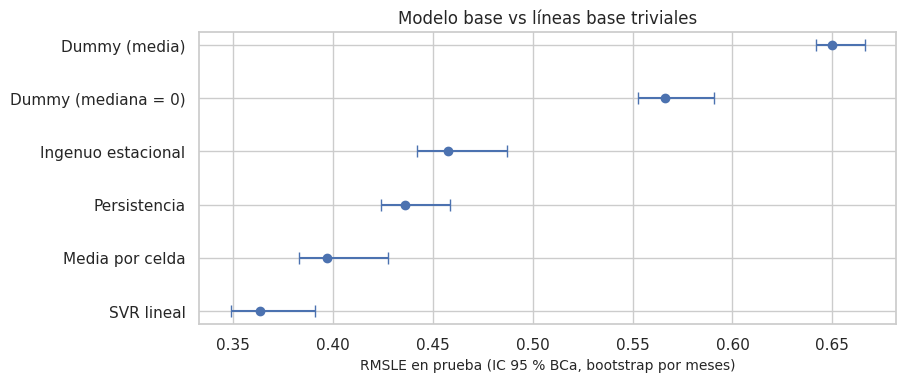

In [7]:
# RMSLE en prueba con IC 95 % BCa (bootstrap por meses)
fig, ax = plt.subplots(figsize=(9, 3.8))
orden = ic_rmsle.sort_values("valor")
ax.errorbar(orden.valor, orden.index, xerr=[orden.valor - orden.IC_BCa_inf, orden.IC_BCa_sup - orden.valor], fmt="o", capsize=4)
ax.set_xlabel("RMSLE en prueba (IC 95 % BCa, bootstrap por meses)"); ax.set_title("Modelo base vs líneas base triviales")
eda.guardar_figura(fig, "11_rmsle_ic.png"); plt.show()

### Comparación explícita con las líneas base triviales

- **Diferencia de RMSLE** entre cada línea base y el SVR lineal, con IC por bootstrap de meses.
- **Prueba de Diebold-Mariano** con corrección de Harvey-Leybourne-Newbold
  {cite}`diebold1995comparing,harvey1997testing`, sobre la serie de pérdidas mensuales (error cuadrático
  en log1p promediado por mes), con varianza de Newey-West.
- **Corrección de Holm** por las cinco comparaciones.

In [8]:
# SVR frente a cada línea trivial: Diebold-Mariano y bootstrap de la diferencia por meses
_, L_svr = ev.perdida_mensual(y[te], preds["SVR lineal"], tm[te])
filas = []
for n in nombres[:-1]:
    _, L_b = ev.perdida_mensual(y[te], preds[n], tm[te])
    dm = ev.diebold_mariano(L_b, L_svr)
    bd = ev.bootstrap_diferencia(y[te], preds[n], preds["SVR lineal"], tm[te])
    filas.append({"línea base": n, "RMSLE_base − RMSLE_SVR": bd["dif"], "IC95_inf": bd["IC_inf"], "IC95_sup": bd["IC_sup"],
                  "DM_HLN": dm["DM_HLN"], "p_DM": dm["p"], "meses": dm["T"]})
comp = pd.DataFrame(filas)
comp["p_DM_Holm"] = eda.holm(comp.p_DM)
comp["veredicto"] = np.where((comp.p_DM_Holm < 0.05) & (comp["RMSLE_base − RMSLE_SVR"] > 0), "SVR mejor",
                             np.where((comp.p_DM_Holm < 0.05), "línea base mejor", "sin diferencia significativa"))
eda.guardar_tabla(comp, "diferencias_vs_triviales.csv")
comp.round(4)

,línea base,RMSLE_base − RMSLE_SVR,IC95_inf,IC95_sup,DM_HLN,p_DM,meses,p_DM_Holm,veredicto
0,Dummy (media),0.2863,0.2741,0.2969,104.4756,0.0,69,0.0,SVR mejor
1,Dummy (mediana = 0),0.2027,0.1962,0.2091,33.0112,0.0,69,0.0,SVR mejor
2,Media por celda,0.0336,0.0264,0.0411,12.3711,0.0,69,0.0,SVR mejor
3,Persistencia,0.0727,0.0650,0.0804,20.6809,0.0,69,0.0,SVR mejor
4,Ingenuo estacional,0.0939,0.0859,0.1022,20.7419,0.0,69,0.0,SVR mejor


In [9]:
# Lectura de las métricas en prueba
r_ = res.loc["SVR lineal"]
mejor_triv = res.drop(index="SVR lineal").RMSLE.idxmin()
md(f"""**Interpretación de las métricas en la prueba.**
- **Métrica principal.** El SVR lineal obtiene **RMSLE = {es(r_.RMSLE, 3)}** (IC 95 % BCa: {es(ic_rmsle.loc['SVR lineal', 'IC_BCa_inf'], 3)}–{es(ic_rmsle.loc['SVR lineal', 'IC_BCa_sup'], 3)}).
  La mejor línea base trivial es **{mejor_triv}**, con {es(res.loc[mejor_triv, 'RMSLE'], 3)}.
- **Comparación con las triviales.** El SVR es significativamente mejor que {int((comp.veredicto == 'SVR mejor').sum())} de las {len(comp)} líneas base
  (Diebold-Mariano HLN con Holm).
- **R² en log = {es(r_.R2_log, 3)}.** El modelo explica cerca de la mitad de la variación del log del conteo. Es un resultado razonable y, sobre todo,
  **lejos del 80–90 %** que exigiría revisar fuga (sección 11.9).
- **R² en conteos = {es(r_.R2, 3)}{' (negativo)' if r_.R2 < 0 else ''}.** Hay que leerlo con cuidado: el modelo se entrena en escala log y, al
  devolver con `expm1`, los errores en los meses extremos del nido se amplifican. Por eso el RMSE ({es(r_.RMSE, 2)}) es
  {('mayor' if r_.RMSE > res.loc['Dummy (media)', 'RMSE'] else 'menor')} que el del Dummy de la media ({es(res.loc['Dummy (media)', 'RMSE'], 2)}): el RMSE premia
  acertar los pocos meses con cientos de sismos, que el RMSLE (la métrica elegida) pondera en proporción.
- **MAPE (solo y > 0) = {es(r_['MAPE_y>0_%'], 1)} %; sMAPE = {es(r_['sMAPE_%'], 1)} %.** Errores relativos grandes, esperables con conteos pequeños: con y = 1,
  predecir 0,5 ya es un error del 50 %.""")

**Interpretación de las métricas en la prueba.**
- **Métrica principal.** El SVR lineal obtiene **RMSLE = 0,364** (IC 95 % BCa: 0,349–0,391).
  La mejor línea base trivial es **Media por celda**, con 0,397.
- **Comparación con las triviales.** El SVR es significativamente mejor que 5 de las 5 líneas base
  (Diebold-Mariano HLN con Holm).
- **R² en log = 0,522.** El modelo explica cerca de la mitad de la variación del log del conteo. Es un resultado razonable y, sobre todo,
  **lejos del 80–90 %** que exigiría revisar fuga (sección 11.9).
- **R² en conteos = 0,291.** Hay que leerlo con cuidado: el modelo se entrena en escala log y, al
  devolver con `expm1`, los errores en los meses extremos del nido se amplifican. Por eso el RMSE (7,91) es
  menor que el del Dummy de la media (9,39): el RMSE premia
  acertar los pocos meses con cientos de sismos, que el RMSLE (la métrica elegida) pondera en proporción.
- **MAPE (solo y > 0) = 78,3 %; sMAPE = 116,4 %.** Errores relativos grandes, esperables con conteos pequeños: con y = 1,
  predecir 0,5 ya es un error del 50 %.

## 11.4 Diagnóstico de residuos

Los residuos se analizan en la escala del modelo, r = log(1 + y) − log(1 + ŷ), que es la escala de la
métrica principal. Se revisan:

1. **normalidad:** histograma, QQ y Jarque-Bera;
2. **heterocedasticidad:** White y Breusch-Pagan contra los valores ajustados;
3. **independencia temporal:** ACF del residuo medio mensual, Ljung-Box y BDS;
4. **independencia espacial:** I de Moran del residuo medio por celda.

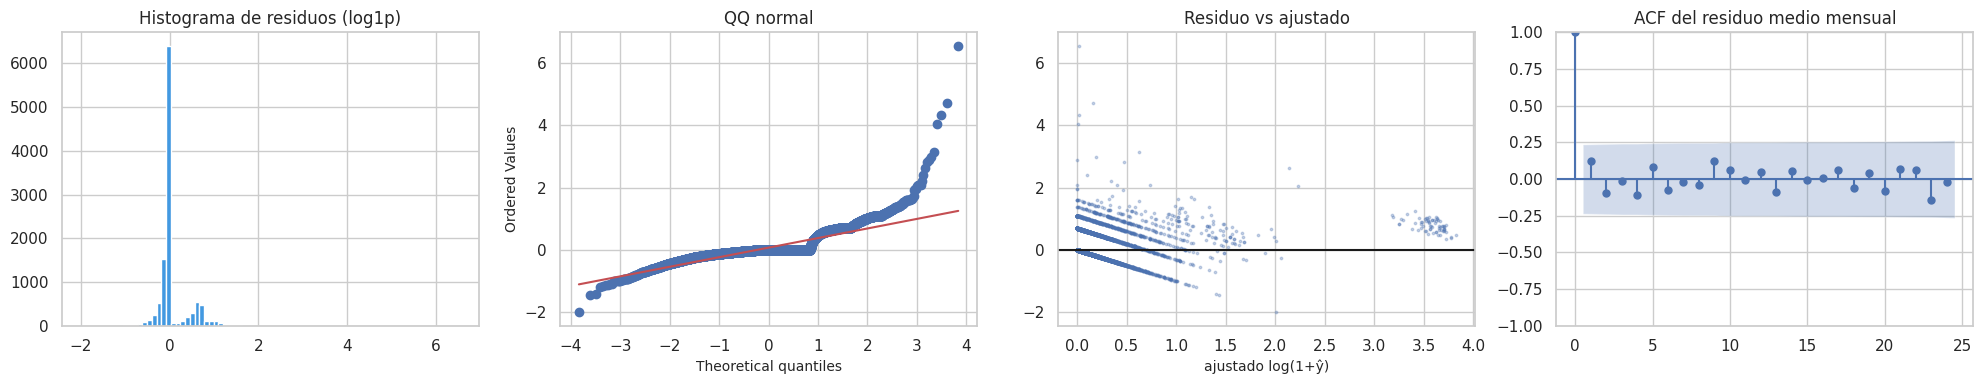

,JB_estad,JB_p,asimetria,curtosis_exceso,White_LM,White_p,BP_LM,BP_p,BDS_estad,BDS_p
0,189810.4365,0.0,2.447,19.5214,328.6925,0.0,249.7664,0.0,8.1163,0.0


,rezago,lb_stat,lb_pvalue
0,1,1.0592,0.3034
1,3,1.7160,0.6334
2,6,3.5619,0.7357
3,12,5.3760,0.9442


In [10]:
# Diagnóstico de residuos del SVR: pruebas de forma y Ljung-Box sobre el residuo mensual
lp_te = np.log1p(np.clip(preds["SVR lineal"], 0, None))
res_te = np.log1p(y[te]) - lp_te
pr = ev.pruebas_residuos(res_te, lp_te)
meses_te, _ = ev.perdida_mensual(y[te], preds["SVR lineal"], tm[te])
r_mes = pd.Series(res_te).groupby(tm[te]).mean()
lb = ev.ljung_box(r_mes.values)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(res_te, bins=80, color="#4299e1"); axes[0].set_title("Histograma de residuos (log1p)")
stats.probplot(res_te, dist="norm", plot=axes[1]); axes[1].set_title("QQ normal")
axes[2].scatter(lp_te, res_te, s=3, alpha=0.3); axes[2].axhline(0, c="k"); axes[2].set_xlabel("ajustado log(1+ŷ)"); axes[2].set_title("Residuo vs ajustado")
plot_acf(r_mes.values, lags=24, ax=axes[3]); axes[3].set_title("ACF del residuo medio mensual")
plt.tight_layout(); eda.guardar_figura(fig, "11_residuos.png"); plt.show()
eda.guardar_tabla(pd.DataFrame([pr]), "diagnostico_residuos.csv")
display(pd.DataFrame([pr]).round(4))
lb.round(4)

In [11]:
# Dependencia espacial de los residuos (I de Moran por celda y por mes)
rc = pd.DataFrame({"celda": cc[te], "r": res_te}).groupby("celda").r.mean()
la_, lo_ = datos.centro_celda(rc.index.to_numpy())
moran_res = eda.moran_global(rc.values, eda.pesos_knn(la_, lo_, 8))
moran_mes = []
for m_ in np.unique(tm[te])[::3]:
    sel_ = tm[te] == m_
    rr = pd.Series(res_te[sel_]).groupby(cc[te][sel_]).mean()
    a_, b_ = datos.centro_celda(rr.index.to_numpy())
    moran_mes.append(eda.moran_global(rr.values, eda.pesos_knn(a_, b_, 8), permutaciones=199)["I"])
lb_celda = []
for c_ in np.unique(cc[te]):
    s_ = res_te[cc[te] == c_]
    if s_.std() > 0:
        lb_celda.append(float(ev.ljung_box(s_, lags=(3,)).lb_pvalue.iloc[0]))
eda.guardar_tabla(pd.DataFrame([{"I_moran_residuo_medio_celda": moran_res["I"], "p": moran_res["p"],
                                 "I_moran_mensual_media": np.mean(moran_mes), "frac_celdas_LjungBox_p<0.05": np.mean(np.array(lb_celda) < 0.05)}]),
                  "residuos_espacio_tiempo.csv")
md(f"""**Interpretación de los residuos.**
- **Normalidad: no.** Asimetría {es(pr['asimetria'], 2)}, curtosis en exceso {es(pr['curtosis_exceso'], 1)}, Jarque-Bera p {p_fmt(pr['JB_p'])}. Es esperable con un objetivo
  discreto con 76 % de ceros: el residuo tiene una masa en valores negativos pequeños (meses sin sismos donde se pronosticaba algo) y una
  cola positiva (enjambres no anticipados). La normalidad no es necesaria para el pronóstico; sí impide usar intervalos paramétricos, por eso
  se usa bootstrap.
- **Heterocedasticidad: sí.** White p {p_fmt(pr['White_p'])} y Breusch-Pagan p {p_fmt(pr['BP_p'])}. La varianza del residuo crece con el nivel pronosticado: las
  celdas activas son más volátiles (embudo en la figura).
- **Independencia temporal.**
  - El residuo medio mensual {'tiene' if (lb.lb_pvalue < 0.05).any() else 'no tiene'} autocorrelación significativa (Ljung-Box p = {', '.join(es(v, 3) for v in lb.lb_pvalue)}
    para rezagos {', '.join(str(int(v)) for v in lb.rezago)}): a nivel agregado no quedan rachas de meses con error del mismo signo.
  - Dentro de cada celda, solo el {es(np.mean(np.array(lb_celda) < 0.05), 0, pct=True)} de las celdas tiene Ljung-Box (3 rezagos) significativo, apenas por encima del 5 %
    que se esperaría por azar.
  - En cambio, BDS (dimensión 2, sobre 3.000 residuos) p {p_fmt(pr['BDS_p'])} {'rechaza' if pr['BDS_p'] < 0.05 else 'no rechaza'} la hipótesis i.i.d. BDS es sensible a dependencia
    **no lineal** y a la heterocedasticidad, no solo a autocorrelación lineal. Su rechazo, junto con Ljung-Box no significativo, apunta a
    estructura no lineal (varianza que cambia con el nivel) más que a autocorrelación serial.
- **Independencia espacial.**
  - El I de Moran del residuo **medio por celda** es {es(moran_res['I'], 3)} (p = {es(moran_res['p'], 3)}): hay sesgos **persistentes por región**, con celdas vecinas que
    el modelo sobreestima o subestima sistemáticamente.
  - Mes a mes, el I de Moran promedio es {es(np.mean(moran_mes), 3)}: el error de un mes concreto no se contagia entre vecinas.
  - Es información espacial que un modelo lineal global no captura (heterogeneidad regional, capítulo 8).
- **Implicación para el Entregable 2.** Los residuos con estructura indican que hay información sin capturar: interacciones no lineales con la
  ubicación, agrupamiento espacio-temporal y celdas con dinámicas distintas. Es la motivación directa para los modelos no lineales y las
  variables de excitación del Entregable 2.""")

**Interpretación de los residuos.**
- **Normalidad: no.** Asimetría 2,45, curtosis en exceso 19,5, Jarque-Bera p < 0,001. Es esperable con un objetivo
  discreto con 76 % de ceros: el residuo tiene una masa en valores negativos pequeños (meses sin sismos donde se pronosticaba algo) y una
  cola positiva (enjambres no anticipados). La normalidad no es necesaria para el pronóstico; sí impide usar intervalos paramétricos, por eso
  se usa bootstrap.
- **Heterocedasticidad: sí.** White p < 0,001 y Breusch-Pagan p < 0,001. La varianza del residuo crece con el nivel pronosticado: las
  celdas activas son más volátiles (embudo en la figura).
- **Independencia temporal.**
  - El residuo medio mensual no tiene autocorrelación significativa (Ljung-Box p = 0,303, 0,633, 0,736, 0,944
    para rezagos 1, 3, 6, 12): a nivel agregado no quedan rachas de meses con error del mismo signo.
  - Dentro de cada celda, solo el 11 % de las celdas tiene Ljung-Box (3 rezagos) significativo, apenas por encima del 5 %
    que se esperaría por azar.
  - En cambio, BDS (dimensión 2, sobre 3.000 residuos) p < 0,001 rechaza la hipótesis i.i.d. BDS es sensible a dependencia
    **no lineal** y a la heterocedasticidad, no solo a autocorrelación lineal. Su rechazo, junto con Ljung-Box no significativo, apunta a
    estructura no lineal (varianza que cambia con el nivel) más que a autocorrelación serial.
- **Independencia espacial.**
  - El I de Moran del residuo **medio por celda** es 0,175 (p = 0,001): hay sesgos **persistentes por región**, con celdas vecinas que
    el modelo sobreestima o subestima sistemáticamente.
  - Mes a mes, el I de Moran promedio es 0,003: el error de un mes concreto no se contagia entre vecinas.
  - Es información espacial que un modelo lineal global no captura (heterogeneidad regional, capítulo 8).
- **Implicación para el Entregable 2.** Los residuos con estructura indican que hay información sin capturar: interacciones no lineales con la
  ubicación, agrupamiento espacio-temporal y celdas con dinámicas distintas. Es la motivación directa para los modelos no lineales y las
  variables de excitación del Entregable 2.

## 11.5 Curva de aprendizaje

Se entrena el SVR con fracciones crecientes de los meses de entrenamiento, siempre los más recientes
antes del bloque de validación. El bloque de validación son los últimos 24 meses del entrenamiento,
con gap. Se mide el RMSLE en la parte de ajuste y en la de validación.

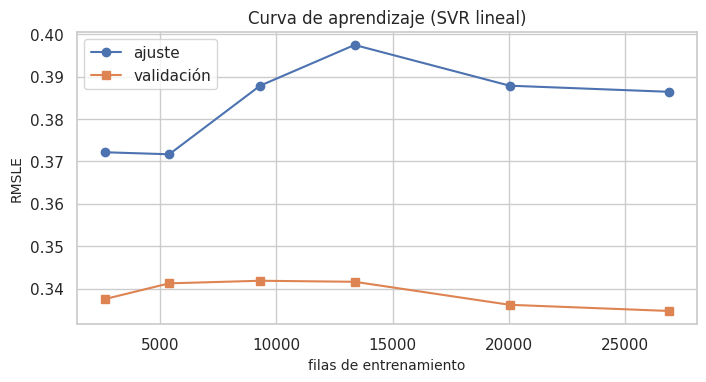

,fraccion_meses,meses,filas,RMSLE_ajuste,RMSLE_validacion
0,0.10,16,2608,0.3722,0.3375
1,0.20,33,5379,0.3717,0.3412
2,0.35,57,9291,0.3878,0.3418
3,0.50,82,13366,0.3975,0.3416
4,0.75,123,20049,0.3879,0.3362
5,1.00,165,26895,0.3864,0.3347


In [12]:
# Curva de aprendizaje: error en validación con fracciones crecientes del entrenamiento
meses_tr = np.unique(tm[tr])
val_ini = meses_tr[-24]
idx_val = tr[tm[tr] >= val_ini]
disp = meses_tr[meses_tr < val_ini - cfg.GAP_MESES]
filas = []
for frac in (0.1, 0.2, 0.35, 0.5, 0.75, 1.0):
    m_sel = disp[-max(6, int(len(disp) * frac)):]
    idx_a = tr[np.isin(tm[tr], m_sel)]
    m_ = mdl.svr_lineal(COLS, C=C_OPT, epsilon=EPS_OPT, imputacion_magnitud=IMPUT).fit(X.iloc[idx_a][COLS], y[idx_a])
    filas.append({"fraccion_meses": frac, "meses": len(m_sel), "filas": len(idx_a),
                  "RMSLE_ajuste": ev.rmsle(y[idx_a], m_.predict(X.iloc[idx_a][COLS])),
                  "RMSLE_validacion": ev.rmsle(y[idx_val], m_.predict(X.iloc[idx_val][COLS]))})
lc = pd.DataFrame(filas)
eda.guardar_tabla(lc, "curva_aprendizaje.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(lc.filas, lc.RMSLE_ajuste, "o-", label="ajuste"); ax.plot(lc.filas, lc.RMSLE_validacion, "s-", label="validación")
ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("RMSLE"); ax.legend(); ax.set_title("Curva de aprendizaje (SVR lineal)")
eda.guardar_figura(fig, "11_curva_aprendizaje.png"); plt.show()
lc.round(4)

In [13]:
md(f"""**Interpretación.**
- **Sin sobreajuste.** El error de validación ({es(lc.RMSLE_validacion.iloc[-1], 3)}) no es peor que el de ajuste ({es(lc.RMSLE_ajuste.iloc[-1], 3)}) con ningún tamaño. El bloque
  de validación (2019–2020) resulta un periodo algo más fácil que el promedio de los años de ajuste.
- **Tamaño de muestra suficiente.** La curva de validación {('se estabiliza' if abs(lc.RMSLE_validacion.iloc[-1] - lc.RMSLE_validacion.iloc[-3]) < 0.01 else 'todavía cambia')} al pasar de
  {lc.filas.iloc[-3]} a {lc.filas.iloc[-1]} filas: más meses de historia aportan poco a un modelo **lineal**.
- **Diagnóstico: sesgo, no varianza.** El límite del SVR lineal es su capacidad (es demasiado simple para relaciones no lineales), no la cantidad de
  datos. Es otra motivación para los modelos no lineales del Entregable 2.""")

**Interpretación.**
- **Sin sobreajuste.** El error de validación (0,335) no es peor que el de ajuste (0,386) con ningún tamaño. El bloque
  de validación (2019–2020) resulta un periodo algo más fácil que el promedio de los años de ajuste.
- **Tamaño de muestra suficiente.** La curva de validación se estabiliza al pasar de
  13366 a 26895 filas: más meses de historia aportan poco a un modelo **lineal**.
- **Diagnóstico: sesgo, no varianza.** El límite del SVR lineal es su capacidad (es demasiado simple para relaciones no lineales), no la cantidad de
  datos. Es otra motivación para los modelos no lineales del Entregable 2.

## 11.6 Interpretación de los coeficientes

Los coeficientes están en unidades de **log(1 + y) por desviación estándar** de cada entrada
transformada (conteos en log1p). Con la colinealidad de los bloques (capítulo 5), los coeficientes
individuales dentro de un bloque no son estables. Por eso se leen también **sumados por bloque**.

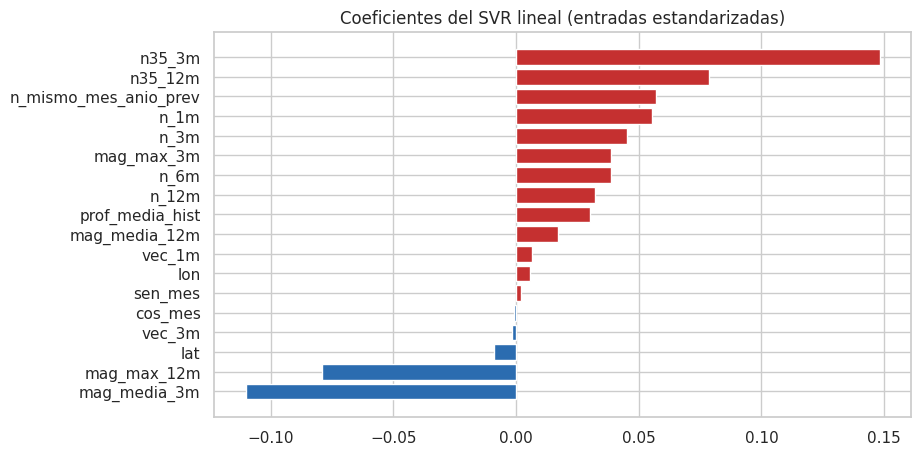

,suma,suma_abs
bloque,,
magnitudes,-0.133,0.245
conteos propios,0.228,0.228
"conteos M ≥ 3,5",0.227,0.227
profundidad,0.030,0.030
ubicación,-0.003,0.015
vecindad,0.005,0.008
calendario,0.001,0.003


**Interpretación.**
- **Tres bloques con peso parecido** (suma de |coef|):
  - **Conteos propios** (0,228): todos positivos. A más sismos recientes en la celda, más se esperan el mes siguiente; el
    peso se reparte entre las ventanas de 1 a 12 meses y el mismo mes del año anterior.
  - **Conteos M ≥ 3,5** (0,227): positivos. `n35_3m` es el coeficiente individual más grande
    (0,148): los sismos moderados recientes anuncian más actividad (réplicas).
  - **Magnitudes** (0,245): con suma **negativa** (-0,133). Como los conteos ya están en
    el modelo, se leen como contraste: a igual número de sismos, una magnitud media más alta indica actividad **esporádica de eventos
    más grandes** y no un enjambre persistente de sismos pequeños (como el del nido), y se asocia a menos sismos al mes siguiente.
- **Vecindad** (suma 0,005) y **ubicación** aportan poco al modelo lineal. Su relación es no lineal (capítulos 5 y 8).
- **Calendario: coeficientes ≈ 0** (0,003 en valor absoluto), coherente con la ausencia de estacionalidad.
- **No son efectos causales.** Los coeficientes describen asociaciones predictivas.

In [14]:
# Interpretación: coeficientes del SVR lineal agrupados por bloque de variables
nombres_x = svr.regressor_.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({"variable": nombres_x, "coef": svr.regressor_.named_steps["svr"].coef_})
bloq = {**{c: "conteos propios" for c in ["n_1m", "n_3m", "n_6m", "n_12m", "n_mismo_mes_anio_prev"]},
        **{c: "conteos M ≥ 3,5" for c in ["n35_3m", "n35_12m"]}, **{c: "vecindad" for c in ["vec_1m", "vec_3m"]},
        **{c: "magnitudes" for c in mdl.MAGNITUDES}, "prof_media_hist": "profundidad",
        "sen_mes": "calendario", "cos_mes": "calendario", "lat": "ubicación", "lon": "ubicación"}
coef["bloque"] = coef.variable.map(bloq)
por_bloque = coef.groupby("bloque").coef.agg(["sum", lambda s: s.abs().sum()]).rename(columns={"sum": "suma", "<lambda_0>": "suma_abs"}).sort_values("suma_abs", ascending=False)
eda.guardar_tabla(coef, "coeficientes_svr.csv")
fig, ax = plt.subplots(figsize=(9, 5))
cs = coef.sort_values("coef")
ax.barh(cs.variable, cs.coef, color=np.where(cs.coef > 0, "#c53030", "#2b6cb0")); ax.set_title("Coeficientes del SVR lineal (entradas estandarizadas)")
eda.guardar_figura(fig, "11_coeficientes.png"); plt.show()
display(por_bloque.round(3))
md(f"""**Interpretación.**
- **Tres bloques con peso parecido** (suma de |coef|):
  - **Conteos propios** ({es(por_bloque.loc['conteos propios', 'suma_abs'], 3)}): todos positivos. A más sismos recientes en la celda, más se esperan el mes siguiente; el
    peso se reparte entre las ventanas de 1 a 12 meses y el mismo mes del año anterior.
  - **Conteos M ≥ 3,5** ({es(por_bloque.loc['conteos M ≥ 3,5', 'suma_abs'], 3)}): positivos. `n35_3m` es el coeficiente individual más grande
    ({es(coef.set_index('variable').loc['n35_3m', 'coef'], 3)}): los sismos moderados recientes anuncian más actividad (réplicas).
  - **Magnitudes** ({es(por_bloque.loc['magnitudes', 'suma_abs'], 3)}): con suma **negativa** ({es(por_bloque.loc['magnitudes', 'suma'], 3)}). Como los conteos ya están en
    el modelo, se leen como contraste: a igual número de sismos, una magnitud media más alta indica actividad **esporádica de eventos
    más grandes** y no un enjambre persistente de sismos pequeños (como el del nido), y se asocia a menos sismos al mes siguiente.
- **Vecindad** (suma {es(por_bloque.loc['vecindad', 'suma'], 3)}) y **ubicación** aportan poco al modelo lineal. Su relación es no lineal (capítulos 5 y 8).
- **Calendario: coeficientes ≈ 0** ({es(por_bloque.loc['calendario', 'suma_abs'], 3)} en valor absoluto), coherente con la ausencia de estacionalidad.
- **No son efectos causales.** Los coeficientes describen asociaciones predictivas.""")

## 11.7 Desempeño por subgrupos y por año de la prueba

In [15]:
# Error por subgrupos: tercil de actividad de la celda y año
media_tr_celda = pd.Series(y[tr]).groupby(cc[tr]).mean()
terc = pd.qcut(media_tr_celda, 3, labels=["baja", "media", "alta"])
g_te = pd.Series(cc[te]).map(terc).to_numpy()
anio_te = datos.fecha_de_mes(tm[te]).year
filas = []
for etiqueta, grupos in (("actividad de la celda (tercil en entrenamiento)", g_te), ("año de la prueba", anio_te)):
    for g_ in pd.unique(grupos):
        s_ = grupos == g_
        filas.append({"criterio": etiqueta, "grupo": str(g_), "filas": int(s_.sum()),
                      "RMSLE_SVR": ev.rmsle(y[te][s_], preds["SVR lineal"][s_]),
                      "RMSLE_media_celda": ev.rmsle(y[te][s_], preds["Media por celda"][s_]),
                      "RMSLE_Dummy_mediana": ev.rmsle(y[te][s_], preds["Dummy (mediana = 0)"][s_])})
sub = pd.DataFrame(filas)
eda.guardar_tabla(sub, "desempeno_subgrupos.csv")
sub.round(4)

,criterio,grupo,filas,RMSLE_SVR,RMSLE_media_celda,RMSLE_Dummy_mediana
0,actividad de la celda (tercil en entrenamiento),baja,3795,0.2367,0.2351,0.2411
1,actividad de la celda (tercil en entrenamiento),alta,3795,0.4966,0.5636,0.8904
2,actividad de la celda (tercil en entrenamiento),media,3657,0.3039,0.3134,0.3209
3,año de la prueba,2021,1956,0.3453,0.3736,0.5442
4,año de la prueba,2022,1956,0.3390,0.3728,0.5281
5,año de la prueba,2023,1956,0.3625,0.3990,0.5689
6,año de la prueba,2024,1956,0.3574,0.3944,0.5724
7,año de la prueba,2025,1956,0.3517,0.3818,0.5696
8,año de la prueba,2026,1467,0.4365,0.4733,0.6248


In [16]:
# Lectura del error por subgrupos
sa = sub[sub.criterio.str.startswith("actividad")].set_index("grupo")
md(f"""**Interpretación.**
- **Por actividad de la celda.** El error crece con la actividad: RMSLE {es(sa.loc['baja', 'RMSLE_SVR'], 3)} en el tercil bajo y {es(sa.loc['alta', 'RMSLE_SVR'], 3)} en el alto.
  En las celdas tranquilas casi todo es cero y es fácil acertar; en las activas está la información y la dificultad.
- **Dónde gana el SVR.** Supera claramente a la media por celda en las celdas activas ({es(sa.loc['alta', 'RMSLE_SVR'], 3)} frente a {es(sa.loc['alta', 'RMSLE_media_celda'], 3)}), donde la
  historia reciente informa. En el tercil bajo empatan en la práctica ({es(sa.loc['baja', 'RMSLE_SVR'], 3)} frente a {es(sa.loc['baja', 'RMSLE_media_celda'], 3)}).
- **Por año.** El error es estable entre 2021 y 2025 y sube en **2026** (año parcial y el más activo del catálogo, capítulo 2):
  {es(sub[(sub.criterio == 'año de la prueba') & (sub.grupo == '2026')].RMSLE_SVR.iloc[0], 3)} frente a {es(sub[(sub.criterio == 'año de la prueba') & (sub.grupo != '2026')].RMSLE_SVR.mean(), 3)} de media en los demás años.
  Es la deriva moderada detectada en el EDA.""")

**Interpretación.**
- **Por actividad de la celda.** El error crece con la actividad: RMSLE 0,237 en el tercil bajo y 0,497 en el alto.
  En las celdas tranquilas casi todo es cero y es fácil acertar; en las activas está la información y la dificultad.
- **Dónde gana el SVR.** Supera claramente a la media por celda en las celdas activas (0,497 frente a 0,564), donde la
  historia reciente informa. En el tercil bajo empatan en la práctica (0,237 frente a 0,235).
- **Por año.** El error es estable entre 2021 y 2025 y sube en **2026** (año parcial y el más activo del catálogo, capítulo 2):
  0,437 frente a 0,351 de media en los demás años.
  Es la deriva moderada detectada en el EDA.

## 11.8 Representación de entrenamiento, validación y prueba con sus predicciones

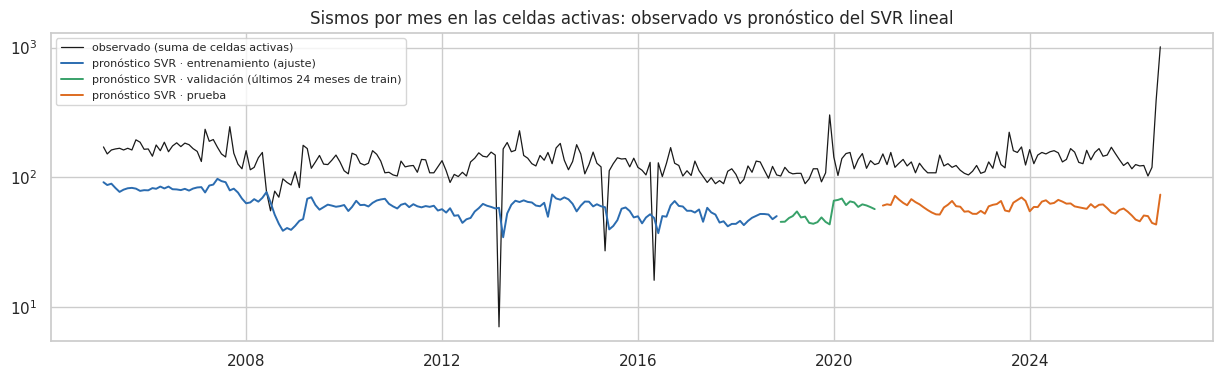

**Interpretación.**
- **Nivel medio.** El SVR sigue el nivel medio de la actividad en las tres particiones, pero **suaviza los picos**: no anticipa los enjambres y
  pronostica menos sismos totales que los observados (suma pronosticada / observada = 0,46 en entrenamiento y
  0,39 en prueba).
- **Por qué.** Es consecuencia de entrenar en escala log, que estima algo cercano a la mediana condicional, y de que los enjambres no se pueden
  anticipar con la historia de la celda.
- **Consistencia entre particiones.** El ajuste no es mejor en entrenamiento que en prueba, otra señal de que no hay sobreajuste.

In [17]:
# Serie total observada frente a la predicha (entrenamiento y prueba)
serie_obs = pd.Series(y).groupby(tm).sum()
pred_full = np.full(len(y), np.nan); pred_full[tr] = pred_tr_svr; pred_full[te] = preds["SVR lineal"]
serie_pred = pd.Series(pred_full).groupby(tm).sum(min_count=1)
fechas = datos.fecha_de_mes(serie_obs.index)
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(fechas, serie_obs.values, lw=0.9, c="k", label="observado (suma de celdas activas)")
for nombre, idx, color in (("entrenamiento (ajuste)", tr[tm[tr] < val_ini], "#2b6cb0"), ("validación (últimos 24 meses de train)", idx_val, "#38a169"), ("prueba", te, "#dd6b20")):
    s_ = pd.Series(pred_full[idx]).groupby(tm[idx]).sum()
    ax.plot(datos.fecha_de_mes(s_.index), s_.values, lw=1.4, c=color, label=f"pronóstico SVR · {nombre}")
ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title("Sismos por mes en las celdas activas: observado vs pronóstico del SVR lineal")
eda.guardar_figura(fig, "11_series_particiones.png"); plt.show()
razon = {n_: np.nansum(pred_full[i_]) / y[i_].sum() for n_, i_ in (("entrenamiento", tr), ("prueba", te))}
md(f"""**Interpretación.**
- **Nivel medio.** El SVR sigue el nivel medio de la actividad en las tres particiones, pero **suaviza los picos**: no anticipa los enjambres y
  pronostica menos sismos totales que los observados (suma pronosticada / observada = {es(razon['entrenamiento'], 2)} en entrenamiento y
  {es(razon['prueba'], 2)} en prueba).
- **Por qué.** Es consecuencia de entrenar en escala log, que estima algo cercano a la mediana condicional, y de que los enjambres no se pueden
  anticipar con la historia de la celda.
- **Consistencia entre particiones.** El ajuste no es mejor en entrenamiento que en prueba, otra señal de que no hay sobreajuste.""")

## 11.9 Nota crítica del enunciado: ¿desempeño sospechosamente alto?

In [18]:
# Notas de verificación: R², auditoría de fuga y esquema de validación
nota = pd.DataFrame([
    ("R² (escala log) del SVR lineal en prueba", es(res.loc['SVR lineal', 'R2_log'], 3), "< 0,80: no hay señal de desempeño sospechoso"),
    ("R² (conteos) del SVR lineal en prueba", es(res.loc['SVR lineal', 'R2'], 3), "< 0,80"),
    ("Mayor R² univariado de una predictora (cap. 9)", es(pd.read_csv(cfg.TABLAS / 'auditoria_univariado.csv').R2_univariado_log_OOF.max(), 3), "sin proxies del objetivo"),
    ("Auditoría de fuga (cap. 9)", "limpia", "variables solo del pasado; partición cronológica con gap"),
    ("Validación respeta tiempo y espacio", "sí", "CV temporal; bloques espaciales aparte; KFold solo como contraste"),
    ("Comparación con la trivial", f"mejora en RMSLE frente a la mediana 0: {es(res.loc['Dummy (mediana = 0)', 'RMSLE'] - res.loc['SVR lineal', 'RMSLE'], 3)}", "no es un acierto trivial"),
    ("¿Problema trivial?", "no", "R² log ≈ 0,5; enjambres no anticipables; residuos con estructura"),
], columns=["chequeo", "resultado", "lectura"])
eda.guardar_tabla(nota, "nota_critica.csv")
nota

,chequeo,resultado,lectura
0,R² (escala log) del SVR lineal en prueba,"0,522","< 0,80: no hay señal de desempeño sospechoso"
1,R² (conteos) del SVR lineal en prueba,"0,291","< 0,80"
2,Mayor R² univariado de una predictora (cap. 9),"0,481",sin proxies del objetivo
3,Auditoría de fuga (cap. 9),limpia,variables solo del pasado; partición cronológi...
4,Validación respeta tiempo y espacio,sí,CV temporal; bloques espaciales aparte; KFold ...
5,Comparación con la trivial,"mejora en RMSLE frente a la mediana 0: 0,203",no es un acierto trivial
6,¿Problema trivial?,no,"R² log ≈ 0,5; enjambres no anticipables; resid..."


**Conclusión del modelo base.**

- **Mejor que lo trivial, sin exagerar.** El SVR lineal supera a las líneas base en RMSLE con un
  desempeño moderado: R² en log ≈ 0,5, muy por debajo del umbral del 80 % de la nota crítica.
- **Diseño válido.** La auditoría de fuga está limpia y la validación respeta la estructura temporal y
  espacial.
- **Lo que el modelo lineal no captura.** Los residuos muestran heterocedasticidad, dependencia temporal y
  espacial y errores mayores en las celdas activas.
- **Siguiente paso.** Eso motiva los modelos benchmark no lineales y la optimización del Entregable 2.